# TA5 Part 1: Heart Disease Classification

**Author:** Whitty, Juan Angelo Roy B <br>
Ebrahim, Fathi Mahad 
<br>**Dataset:** `datasets/heart_v2.csv`  
**Model:** Random Forest classifier

We assess class balance, compare three validation methods, and tune three
hyperparameters using grid search and Bayesian optimization. Accuracy, precision,
recall, F1, and confusion matrices describe performance on a separate test set.
The target is `heart disease`; class `1` is the positive class throughout.

## 1. Setup and reproducibility

In [1]:
from pathlib import Path
import hashlib
import platform
import time
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    make_scorer, classification_report, confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.model_selection import (
    train_test_split, KFold, StratifiedKFold, ShuffleSplit,
    cross_validate, GridSearchCV, ParameterGrid,
)
from skopt import BayesSearchCV
from skopt.space import Integer

SEED = 42
TEST_SIZE = 0.20
VALIDATION_SIZE = 0.20
N_SPLITS = 5
BALANCE_THRESHOLD = 0.60
SEARCH_JOBS = 1  # One worker avoids Windows process-cleanup warnings.
BAYES_INITIAL_POINTS = 10
pd.set_option('display.max_columns', 20)
plt.rcParams.update({
    'figure.dpi': 120, 'font.size': 11, 'axes.titlesize': 13,
    'axes.spines.top': False, 'axes.spines.right': False,
})
display(pd.DataFrame({
    'Component': ['Python', 'pandas', 'numpy', 'matplotlib',
                  'scikit-learn', 'scikit-optimize'],
    'Version': [platform.python_version()] + [
        version(package) for package in
        ['pandas', 'numpy', 'matplotlib', 'scikit-learn', 'scikit-optimize']
    ],
}))

def describe_balance(counts):
    majority_share = counts.max() / counts.sum()
    label = ('approximately balanced' if majority_share <= BALANCE_THRESHOLD
             else 'imbalanced under the stated lab rule')
    return label, majority_share


def prediction_metrics(actual, predicted):
    matrix = confusion_matrix(actual, predicted, labels=[0, 1])
    tn, fp, fn, tp = matrix.ravel()
    metrics = {
        'Accuracy': accuracy_score(actual, predicted),
        'Precision': precision_score(actual, predicted, pos_label=1, zero_division=0),
        'Recall': recall_score(actual, predicted, pos_label=1, zero_division=0),
        'F1': f1_score(actual, predicted, pos_label=1, zero_division=0),
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
    }
    return metrics, matrix


def summarize_search(name, search, seconds):
    best = search.best_index_
    return {
        'Search': name,
        'Candidates evaluated': len(search.cv_results_['params']),
        'Best validation F1': search.best_score_,
        'Mean training F1': search.cv_results_['mean_train_score'][best],
        'Training minus validation F1': (
            search.cv_results_['mean_train_score'][best] - search.best_score_),
        'Seconds': seconds,
        'Best parameters': dict(search.best_params_),
    }


,Component,Version
0,Python,3.14.7
1,pandas,3.0.6
2,numpy,2.5.3
3,matplotlib,3.11.2
4,scikit-learn,1.9.1
5,scikit-optimize,0.10.2


## 2. Data inspection

Predictors are `age`, `sex`, `BP`, and `cholestrol` (the source spelling is
preserved). The label column is excluded from the predictors. <br><br> We check missing
values, duplicate rows, class codes, and numerical ranges before splitting.
Extreme observations are retained because the file provides no evidence that
they are recording errors. We do not impute, scale, or resample the data.

In [2]:
DATA_PATH = Path('datasets') / 'heart_v2.csv'

dataset_sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
df = pd.read_csv(DATA_PATH)

FEATURES = ['age', 'sex', 'BP', 'cholestrol']
TARGET = 'heart disease'

assert set(df.columns) == set(FEATURES + [TARGET]), 'Unexpected dataset columns.'
assert df[FEATURES + [TARGET]].notna().all().all(), 'Review missing values before fitting.'
assert set(df[TARGET].unique()) == {0, 1}, 'Expected binary target labels 0 and 1.'
assert set(df['sex'].unique()).issubset({0, 1}), 'Unexpected sex codes.'
assert np.isfinite(df[FEATURES].to_numpy()).all(), 'Predictors must be finite.'

print(f'Rows: {len(df)} | Predictors: {len(FEATURES)}')
print(f'Duplicate rows: {df.duplicated().sum()}')
display(df.head())
display(pd.DataFrame({
    'Data type': df.dtypes.astype(str),
    'Missing values': df.isna().sum(),
    'Unique values': df.nunique(),
}))
display(df.describe().round(2))

Rows: 270 | Predictors: 4
Duplicate rows: 0


,age,sex,BP,cholestrol,heart disease
0,70,1,130,322,1
1,67,0,115,564,0
2,57,1,124,261,1
3,64,1,128,263,0
4,74,0,120,269,0


,Data type,Missing values,Unique values
age,int64,0,41
sex,int64,0,2
BP,int64,0,47
cholestrol,int64,0,144
heart disease,int64,0,2


,age,sex,BP,cholestrol,heart disease
count,270.00,270.00,270.00,270.00,270.00
mean,54.43,0.68,131.34,249.66,0.44
std,9.11,0.47,17.86,51.69,0.50
min,29.00,0.00,94.00,126.00,0.00
25%,48.00,0.00,120.00,213.00,0.00
50%,55.00,1.00,130.00,245.00,0.00
75%,61.00,1.00,140.00,280.00,1.00
max,77.00,1.00,200.00,564.00,1.00


## 3. Is the dataset balanced?

For classification, balance concerns the **target class frequencies**, rather
than the distribution of predictor values. We compute each class proportion
and the imbalance ratio, defined as the majority count divided by the minority
count. A ratio of 1 means exact balance.<br><br>For this lab, a majority share no larger
than the configured `BALANCE_THRESHOLD` (displayed below) is an explicit descriptive rule for calling a binary dataset
approximately balanced; it is not a universal statistical threshold.

,Count,Percentage (%)
Target class,,
0,150,55.56
1,120,44.44


Lab balance threshold: majority share <= 60%
Imbalance ratio = 150 / 120 = 1.25:1
Conclusion: approximately balanced; majority share = 55.56%.


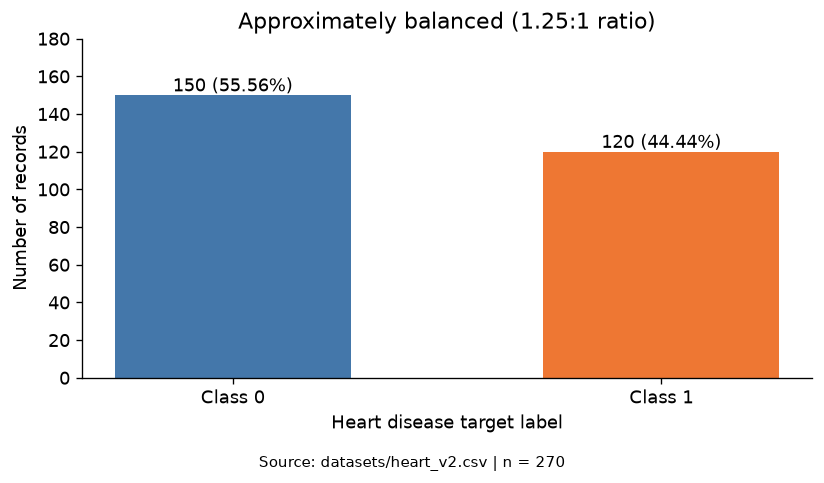

In [3]:
class_counts = df[TARGET].value_counts().sort_index()
class_percentages = class_counts / len(df) * 100
imbalance_ratio = class_counts.max() / class_counts.min()
balance_table = pd.DataFrame({
    'Count': class_counts, 'Percentage (%)': class_percentages,
}).rename_axis('Target class')
display(balance_table.round(2))
balance_label, majority_share = describe_balance(class_counts)
print(f'Lab balance threshold: majority share <= {BALANCE_THRESHOLD:.0%}')
print(f'Imbalance ratio = {class_counts.max()} / {class_counts.min()} = {imbalance_ratio:.2f}:1')
print(f'Conclusion: {balance_label}; majority share = {majority_share:.2%}.')

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(['Class 0', 'Class 1'], class_counts.to_numpy(),
              color=['#4477AA', '#EE7733'], width=0.55)
for bar, count, percentage in zip(bars, class_counts, class_percentages):
    ax.text(bar.get_x() + bar.get_width()/2, count + 2,
            f'{count} ({percentage:.2f}%)', ha='center')
ax.set(title=f'{balance_label.capitalize()} ({imbalance_ratio:.2f}:1 ratio)',
       xlabel='Heart disease target label', ylabel='Number of records',
       ylim=(0, class_counts.max() * 1.20))
fig.text(0.5, 0.01, f'Source: {DATA_PATH.as_posix()} | n = {len(df)}', ha='center', fontsize=9)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

## 4. Hold out the test set and choose a classifier

A stratified 80/20 split preserves the class proportions. The test set remains
outside cross-validation and both searches. Label counts for the full dataset
are descriptive only; we do not use test predictions to choose parameters.

Random Forest combines decision trees to model nonlinear relationships and
interactions. Its splits do not require standardizing age, blood pressure, or
cholesterol. The baseline uses 200 trees, unrestricted depth, and one observation
per leaf. We leave class weights unchanged and do not resample as fixed experiment
choices. Class balance alone does not establish whether resampling would help.

In [4]:
X = df[FEATURES].copy()
y = df[TARGET].copy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED,
)
assert set(X_train.index).isdisjoint(X_test.index)
assert len(X_train) + len(X_test) == len(df)
assert X_train.columns.tolist() == FEATURES and TARGET not in X_train.columns

display(pd.DataFrame({
    'Training count': y_train.value_counts().sort_index(),
    'Test count': y_test.value_counts().sort_index(),
}).rename_axis('Class'))
print(f'Training records: {len(X_train)} | Held-out test records: {len(X_test)}')

baseline = RandomForestClassifier(
    n_estimators=200, max_depth=None, min_samples_leaf=1,
    random_state=SEED, n_jobs=1,
)
scoring = {
    'Accuracy': 'accuracy',
    'Precision': make_scorer(precision_score, pos_label=1, zero_division=0),
    'Recall': make_scorer(recall_score, pos_label=1, zero_division=0),
    'F1': make_scorer(f1_score, pos_label=1, zero_division=0),
}

,Training count,Test count
Class,,
0,120,30
1,96,24


Training records: 216 | Held-out test records: 54


## 5. Compare three cross-validation methods

All methods evaluate the same initial model on training data only:

- **K-fold:** five shuffled, disjoint validation folds, without class stratification.
- **Stratified k-fold:** five shuffled folds with approximately preserved class proportions.
- **Shuffle split:** five independently shuffled 80/20 training/validation splits,
  without stratification. Validation sets may overlap between repetitions.

Each k-fold method uses five folds from one partition, not five repeated
cross-validation runs. Shuffle split uses five independent draws. The summary
uses sample standard deviations (`ddof=1`); search tables later use population
standard deviations (`ddof=0`, scikit-learn convention). These values describe
variation across these splits; they are not confidence intervals. The
cross-validation comparison assesses the baseline. Both later searches use
stratified folds consistently, rather than selecting a validation method from
its observed score.

In [5]:
cv_methods = {
    'K-fold': KFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED),
    'Stratified k-fold': StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED),
    'Shuffle split': ShuffleSplit(n_splits=N_SPLITS, test_size=VALIDATION_SIZE, random_state=SEED),
}
fold_records = []
cv_splits_by_method = {}
for name, splitter in cv_methods.items():
    splits = list(splitter.split(X_train, y_train))
    cv_splits_by_method[name] = splits
    results = cross_validate(
        clone(baseline), X_train, y_train, cv=splits,
        scoring=scoring, n_jobs=SEARCH_JOBS, error_score='raise',
    )
    for fold, (train_idx, val_idx) in enumerate(splits, start=1):
        assert set(train_idx).isdisjoint(val_idx)
        counts = y_train.iloc[val_idx].value_counts().reindex([0, 1], fill_value=0)
        fold_records.append({
            'Method': name, 'Split': fold,
            'Training n': len(train_idx), 'Validation n': len(val_idx),
            'Validation class 0': int(counts.loc[0]),
            'Validation class 1': int(counts.loc[1]),
            **{metric: results[f'test_{metric}'][fold - 1] for metric in scoring},
        })
    print(f'Completed: {name}')

fold_results = pd.DataFrame(fold_records)
cv_summary = fold_results.groupby('Method', sort=False)[list(scoring)].agg(['mean', 'std'])
display(fold_results.round(4))
display(cv_summary.round(4))
assert len(fold_results) == len(cv_methods) * N_SPLITS
assert np.isfinite(fold_results[list(scoring)].to_numpy()).all()

Completed: K-fold
Completed: Stratified k-fold
Completed: Shuffle split


,Method,Split,Training n,Validation n,Validation class 0,Validation class 1,Accuracy,Precision,Recall,F1
0,K-fold,1,172,44,28,16,0.7273,0.5833,0.8750,0.7000
1,K-fold,2,173,43,22,21,0.4884,0.4737,0.4286,0.4500
2,K-fold,3,173,43,27,16,0.5814,0.4286,0.3750,0.4000
3,K-fold,4,173,43,19,24,0.6047,0.7333,0.4583,0.5641
4,K-fold,5,173,43,24,19,0.6744,0.6471,0.5789,0.6111
5,Stratified k-fold,1,172,44,24,20,0.6136,0.5882,0.5000,0.5405
6,Stratified k-fold,2,173,43,24,19,0.5581,0.5000,0.5789,0.5366
7,Stratified k-fold,3,173,43,24,19,0.6047,0.5625,0.4737,0.5143
8,Stratified k-fold,4,173,43,24,19,0.7674,0.7368,0.7368,0.7368
9,Stratified k-fold,5,173,43,24,19,0.6977,0.6364,0.7368,0.6829


Accuracy         Precision          Recall              F1  \
                      mean     std      mean     std    mean     std    mean   
Method                                                                         
K-fold              0.6152  0.0914    0.5732  0.1245  0.5432  0.2000  0.5450   
Stratified k-fold   0.6483  0.0835    0.6048  0.0887  0.6053  0.1262  0.6022   
Shuffle split       0.6773  0.0631    0.6104  0.1452  0.6512  0.1485  0.6193   

                           
                      std  
Method                     
K-fold             0.1213  
Stratified k-fold  0.1006  
Shuffle split      0.1089

## 6. Optimize three hyperparameters

`n_estimators` controls the number of trees; `max_depth` limits tree complexity;
`min_samples_leaf` controls the minimum number of observations in a terminal
node. We optimize positive-class F1, the harmonic mean of precision and recall,
so parameter selection considers both missed positives and false positives.

Grid search exhaustively evaluates the combinations shown below. Bayesian search
uses a Gaussian-process surrogate and expected improvement with the same candidate
budget derived from the grid, including the configured initial random points. Its integer domains have the same bounds
as the grid but also include intermediate values. Equal evaluation budgets
do not make the search spaces identical or guarantee that either method wins.

Both searches use the **same five stratified training folds** and refit their
best configuration on all training records. Best CV F1 is a selection score and
can be optimistic after tuning; the held-out test set provides a separate
evaluation.

In [6]:
tuning_cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
tuning_splits = list(tuning_cv.split(X_train, y_train))
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 6, 12],
    'min_samples_leaf': [1, 3, 5],
}
bayes_space = {
    'n_estimators': Integer(100, 300),
    'max_depth': Integer(3, 12),
    'min_samples_leaf': Integer(1, 5),
}
SEARCH_BUDGET = len(list(ParameterGrid(param_grid)))
print(f'Candidate budget per search: {SEARCH_BUDGET}; initial Bayesian points: {BAYES_INITIAL_POINTS}')
display(pd.DataFrame({
    'Hyperparameter': list(param_grid),
    'Grid values': [str(v) for v in param_grid.values()],
    'Bayesian integer range': ['100 to 300', '3 to 12', '1 to 5'],
}))

grid_search = GridSearchCV(
    estimator=clone(baseline), param_grid=param_grid,
    scoring=scoring['F1'], cv=tuning_splits, refit=True,
    n_jobs=SEARCH_JOBS, error_score='raise', return_train_score=True,
)
started = time.perf_counter()
grid_search.fit(X_train, y_train)
grid_seconds = time.perf_counter() - started
print(f'Grid search completed in {grid_seconds:.1f} seconds.')
print('Best parameters:', grid_search.best_params_)
print(f'Best validation F1: {grid_search.best_score_:.4f}')

Candidate budget per search: 27; initial Bayesian points: 10


,Hyperparameter,Grid values,Bayesian integer range
0,n_estimators,"[100, 200, 300]",100 to 300
1,max_depth,"[3, 6, 12]",3 to 12
2,min_samples_leaf,"[1, 3, 5]",1 to 5


Grid search completed in 30.8 seconds.
Best parameters: {'max_depth': 6, 'min_samples_leaf': 1, 'n_estimators': 300}
Best validation F1: 0.6475


In [7]:
bayes_search = BayesSearchCV(
    estimator=clone(baseline), search_spaces=bayes_space,
    n_iter=SEARCH_BUDGET, scoring=scoring['F1'], cv=tuning_splits, refit=True,
    random_state=SEED, n_jobs=SEARCH_JOBS, error_score='raise',
    return_train_score=True,
    optimizer_kwargs={'base_estimator': 'GP', 'n_initial_points': BAYES_INITIAL_POINTS, 'acq_func': 'EI'},
)

def report_progress(result):
    completed = len(result.func_vals)
    if completed % max(1, SEARCH_BUDGET // 3) == 0 or completed == SEARCH_BUDGET:
        print(f'Bayesian search: {completed}/{SEARCH_BUDGET} evaluations complete.')
    return False

started = time.perf_counter()
bayes_search.fit(X_train, y_train, callback=report_progress)
bayes_seconds = time.perf_counter() - started
print(f'Bayesian search completed in {bayes_seconds:.1f} seconds.')
print('Best parameters:', dict(bayes_search.best_params_))
print(f'Best validation F1: {bayes_search.best_score_:.4f}')

Bayesian search: 9/27 evaluations complete.
Bayesian search: 18/27 evaluations complete.
Bayesian search: 27/27 evaluations complete.
Bayesian search completed in 37.2 seconds.
Best parameters: {'max_depth': 6, 'min_samples_leaf': 1, 'n_estimators': 299}
Best validation F1: 0.6475


In [8]:
searches = {'Grid search': grid_search, 'Bayesian search': bayes_search}
search_summary = pd.DataFrame([
    summarize_search(name, search, seconds)
    for (name, search), seconds in zip(searches.items(), [grid_seconds, bayes_seconds])
])

display(search_summary.round(4))
for name, search in searches.items():
    display(Markdown(f'### {name}: top five configurations'))
    leaderboard = pd.DataFrame(search.cv_results_).sort_values(
        ['rank_test_score'], kind='stable'
    )
    display(leaderboard[[
        'rank_test_score', 'mean_test_score', 'std_test_score',
        'mean_train_score', 'param_n_estimators', 'param_max_depth',
        'param_min_samples_leaf',
    ]].head(5).rename(columns={
        'mean_test_score': 'Mean validation F1',
        'std_test_score': 'Validation F1 SD',
        'mean_train_score': 'Mean training F1',
    }).round(4))
    assert len(search.cv_results_['params']) == SEARCH_BUDGET
    assert np.isfinite(search.cv_results_['mean_test_score']).all()

# Selection occurs before test predictions; exact ties favor grid search.
selected_search_name = ('Bayesian search' if bayes_search.best_score_ > grid_search.best_score_
                        else 'Grid search')
selected_model = searches[selected_search_name].best_estimator_
print(f'Selected by validation F1: {selected_search_name}')

,Search,Candidates evaluated,Best validation F1,Mean training F1,Training minus validation F1,Seconds,Best parameters
0,Grid search,27,0.6475,0.9492,0.3017,30.7943,"{'max_depth': 6, 'min_samples_leaf': 1, 'n_est..."
1,Bayesian search,27,0.6475,0.9505,0.3030,37.2445,"{'max_depth': 6, 'min_samples_leaf': 1, 'n_est..."


### Grid search: top five configurations

,rank_test_score,Mean validation F1,Validation F1 SD,Mean training F1,param_n_estimators,param_max_depth,param_min_samples_leaf
11,1,0.6475,0.0807,0.9492,300,6,1
10,2,0.6417,0.0668,0.9479,200,6,1
19,3,0.6126,0.0890,1.0000,200,12,1
23,4,0.6121,0.0539,0.9028,300,12,3
2,5,0.6101,0.0761,0.7367,300,3,1


### Bayesian search: top five configurations

,rank_test_score,Mean validation F1,Validation F1 SD,Mean training F1,param_n_estimators,param_max_depth,param_min_samples_leaf
19,1,0.6475,0.0807,0.9505,299,6,1
15,2,0.6352,0.0626,0.9767,300,7,1
24,3,0.6303,0.0883,0.9753,101,7,1
16,4,0.6237,0.0715,0.9089,300,6,2
14,5,0.6202,0.0765,1.0000,300,9,1


Selected by validation F1: Grid search


## 7. Held-out classification metrics and confusion matrices

The final model has already been selected. The following test comparison reports
the baseline, both tuned models, and two feature-ignoring dummy benchmarks without
changing that choice. The majority-class benchmark learns its label from training
data; the always-positive benchmark predicts class 1. Both also use the exact
stratified training folds used by the searches. Benchmarks provide context and
never enter model selection.

- Accuracy = (TP + TN) / all predictions.
- Precision = TP / (TP + FP).
- Recall = TP / (TP + FN).
- F1 = 2 * precision * recall / (precision + recall).

The summary uses positive-class metrics. The classification reports also show
per-class results and macro/weighted averages. Confusion matrices use actual
labels on rows and predicted labels on columns, ordered `[0, 1]`, so their
entries are `[[TN, FP], [FN, TP]]`. Undefined precision, recall, or F1 is set to
zero consistently.

### Dummy benchmark stratified CV (SD: ddof=1)

,Benchmark,Split,Accuracy,Precision,Recall,F1
0,Majority class,1,0.5455,0.0000,0.0,0.0000
1,Majority class,2,0.5581,0.0000,0.0,0.0000
2,Majority class,3,0.5581,0.0000,0.0,0.0000
3,Majority class,4,0.5581,0.0000,0.0,0.0000
4,Majority class,5,0.5581,0.0000,0.0,0.0000
5,Always positive,1,0.4545,0.4545,1.0,0.6250
6,Always positive,2,0.4419,0.4419,1.0,0.6129
7,Always positive,3,0.4419,0.4419,1.0,0.6129
8,Always positive,4,0.4419,0.4419,1.0,0.6129
9,Always positive,5,0.4419,0.4419,1.0,0.6129


Accuracy         Precision         Recall           F1        
                    mean     std      mean     std   mean  std    mean     std
Benchmark                                                                     
Majority class    0.5556  0.0057    0.0000  0.0000    0.0  0.0  0.0000  0.0000
Always positive   0.4444  0.0057    0.4444  0.0057    1.0  0.0  0.6153  0.0054

,Selected by CV,Accuracy,Precision,Recall,F1,TN,FP,FN,TP
Model,,,,,,,,,
Baseline,False,0.6111,0.5600,0.5833,0.5714,19,11,10,14
Grid search,True,0.6481,0.5926,0.6667,0.6275,19,11,8,16
Bayesian search,False,0.6481,0.5926,0.6667,0.6275,19,11,8,16
Majority class,False,0.5556,0.0000,0.0000,0.0000,30,0,24,0
Always positive,False,0.4444,0.4444,1.0000,0.6154,0,30,0,24


### Baseline: classification report

              precision    recall  f1-score   support

     Class 0     0.6552    0.6333    0.6441        30
     Class 1     0.5600    0.5833    0.5714        24

    accuracy                         0.6111        54
   macro avg     0.6076    0.6083    0.6077        54
weighted avg     0.6129    0.6111    0.6118        54



### Grid search: classification report

              precision    recall  f1-score   support

     Class 0     0.7037    0.6333    0.6667        30
     Class 1     0.5926    0.6667    0.6275        24

    accuracy                         0.6481        54
   macro avg     0.6481    0.6500    0.6471        54
weighted avg     0.6543    0.6481    0.6492        54



### Bayesian search: classification report

              precision    recall  f1-score   support

     Class 0     0.7037    0.6333    0.6667        30
     Class 1     0.5926    0.6667    0.6275        24

    accuracy                         0.6481        54
   macro avg     0.6481    0.6500    0.6471        54
weighted avg     0.6543    0.6481    0.6492        54



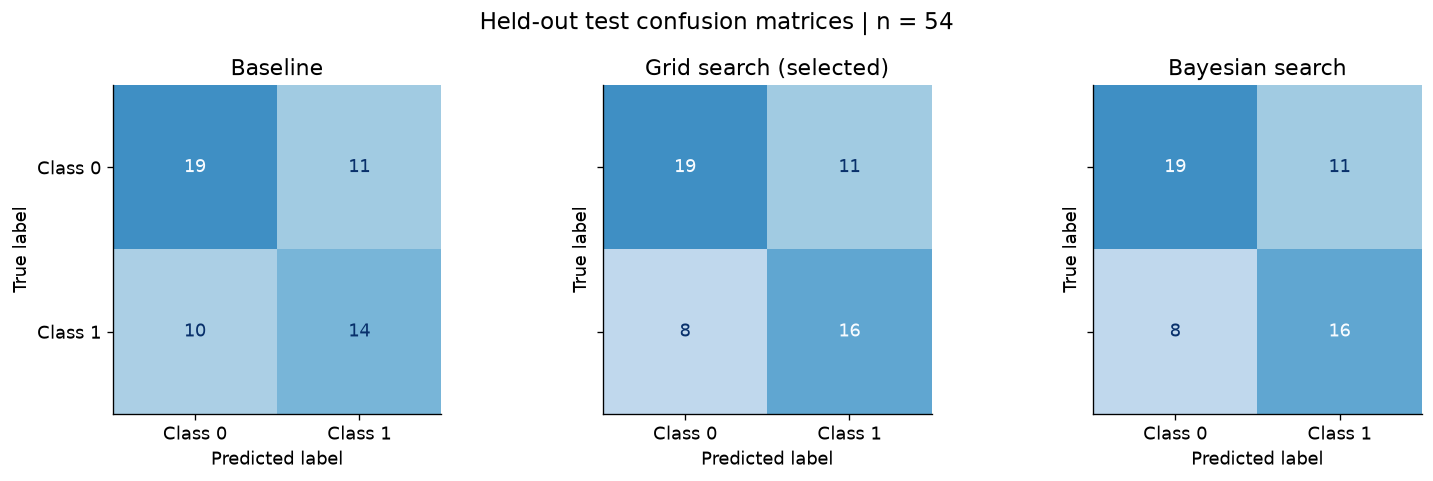

In [9]:
benchmarks = {
    'Majority class': DummyClassifier(strategy='most_frequent'),
    'Always positive': DummyClassifier(strategy='constant', constant=1),
}
benchmark_fold_records = []
for name, model in benchmarks.items():
    scores = cross_validate(
        model, X_train, y_train, cv=tuning_splits, scoring=scoring,
        n_jobs=SEARCH_JOBS, error_score='raise',
    )
    for fold in range(N_SPLITS):
        benchmark_fold_records.append({
            'Benchmark': name, 'Split': fold + 1,
            **{metric: scores[f'test_{metric}'][fold] for metric in scoring},
        })
    model.fit(X_train, y_train)
benchmark_fold_results = pd.DataFrame(benchmark_fold_records)
benchmark_cv_summary = benchmark_fold_results.groupby('Benchmark', sort=False)[
    list(scoring)
].agg(['mean', 'std'])
display(Markdown('### Dummy benchmark stratified CV (SD: ddof=1)'))
display(benchmark_fold_results.round(4))
display(benchmark_cv_summary.round(4))

baseline.fit(X_train, y_train)
models = {
    'Baseline': baseline,
    'Grid search': grid_search.best_estimator_,
    'Bayesian search': bayes_search.best_estimator_,
}
forest_names = list(models)
models.update(benchmarks)
test_records, test_predictions, confusion_matrices = [], {}, {}
for name, model in models.items():
    predictions = model.predict(X_test)
    test_predictions[name] = predictions
    metrics, matrix = prediction_metrics(y_test, predictions)
    confusion_matrices[name] = matrix
    test_records.append({
        'Model': name, 'Selected by CV': name == selected_search_name, **metrics,
    })
    assert matrix.sum() == len(y_test)
    assert np.array_equal(matrix.sum(axis=1), y_test.value_counts().sort_index().to_numpy())
    assert len(predictions) == len(y_test)

test_metrics = pd.DataFrame(test_records).set_index('Model')
display(test_metrics.round(4))
for name in forest_names:
    predictions = test_predictions[name]
    display(Markdown(f'### {name}: classification report'))
    print(classification_report(
        y_test, predictions, labels=[0, 1], target_names=['Class 0', 'Class 1'],
        digits=4, zero_division=0,
    ))

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
common_max = max(matrix.max() for matrix in confusion_matrices.values())
for ax, (name, matrix) in zip(axes, ((name, confusion_matrices[name]) for name in forest_names)):
    ConfusionMatrixDisplay(matrix, display_labels=['Class 0', 'Class 1']).plot(
        ax=ax, cmap='Blues', colorbar=False, values_format='d',
        im_kw={'vmin': 0, 'vmax': common_max},
    )
    ax.set_title(name + (' (selected)' if name == selected_search_name else ''))
fig.suptitle(f'Held-out test confusion matrices | n = {len(y_test)}', fontsize=14)
fig.tight_layout()
plt.show()

## 8. One-paragraph insight

The paragraph below is generated from the computed results, so it updates when
the notebook is rerun.

In [10]:
selected = test_metrics.loc[selected_search_name]
baseline_result = test_metrics.loc['Baseline']
positive_result = test_metrics.loc['Always positive']
selected_search = searches[selected_search_name]
selected_train_f1 = selected_search.cv_results_['mean_train_score'][selected_search.best_index_]
cv_f1_means = cv_summary[('F1', 'mean')]
cv_f1_sds = cv_summary[('F1', 'std')]

def compare_score(value, reference):
    return 'higher' if value > reference else 'lower' if value < reference else 'equal'

overfit_text = ('consistent with overfitting' if selected_train_f1 > selected_search.best_score_
                else 'not evidence of a positive training–validation gap')
insight = (
    f'The dataset is {balance_label}, with {class_counts.loc[0]} class-0 records '
    f'({class_percentages.loc[0]:.2f}%) and {class_counts.loc[1]} class-1 records '
    f'({class_percentages.loc[1]:.2f}%), a {imbalance_ratio:.2f}:1 ratio under the '
    f'{BALANCE_THRESHOLD:.0%} majority-share rule. Leaving resampling and class weights '
    f'unchanged is an experiment choice, not evidence that resampling cannot help. '
    f'Baseline mean CV F1 ranged from {cv_f1_means.min():.4f} to {cv_f1_means.max():.4f}, '
    f'with sample split SDs of {cv_f1_sds.min():.4f}–{cv_f1_sds.max():.4f}. '
    f'Grid and Bayesian best validation F1 were {grid_search.best_score_:.4f} and '
    f'{bayes_search.best_score_:.4f}; {selected_search_name.lower()} was selected by '
    f'validation F1, with exact ties favoring grid. Its mean training F1 '
    f'{selected_train_f1:.4f} versus validation F1 {selected_search.best_score_:.4f} is '
    f'{overfit_text}. On {len(y_test)} held-out records, selected forest accuracy was '
    f'{selected["Accuracy"]:.4f}, precision {selected["Precision"]:.4f}, recall '
    f'{selected["Recall"]:.4f}, and F1 {selected["F1"]:.4f}, with {int(selected["FP"])} '
    f'false positives and {int(selected["FN"])} false negatives. Selected F1 was '
    f'{compare_score(selected["F1"], baseline_result["F1"])} than baseline forest F1 '
    f'{baseline_result["F1"]:.4f} and {compare_score(selected["F1"], positive_result["F1"])} '
    f'than always-positive F1 {positive_result["F1"]:.4f}; versus always-positive '
    f'precision {positive_result["Precision"]:.4f} and recall {positive_result["Recall"]:.4f}, '
    f'the forest had {compare_score(selected["Precision"], positive_result["Precision"])} '
    f'precision and {compare_score(selected["Recall"], positive_result["Recall"])} recall, '
    f'trading fewer false positives for more missed positives. These are observations '
    f'on this split, not statistically established superiority or evidence of reliable '
    f'performance on new populations.'
)
display(Markdown(insight))


The dataset is approximately balanced, with 150 class-0 records (55.56%) and 120 class-1 records (44.44%), a 1.25:1 ratio under the 60% majority-share rule. Leaving resampling and class weights unchanged is an experiment choice, not evidence that resampling cannot help. Baseline mean CV F1 ranged from 0.5450 to 0.6193, with sample split SDs of 0.1006–0.1213. Grid and Bayesian best validation F1 were 0.6475 and 0.6475; grid search was selected by validation F1, with exact ties favoring grid. Its mean training F1 0.9492 versus validation F1 0.6475 is consistent with overfitting. On 54 held-out records, selected forest accuracy was 0.6481, precision 0.5926, recall 0.6667, and F1 0.6275, with 11 false positives and 8 false negatives. Selected F1 was higher than baseline forest F1 0.5714 and higher than always-positive F1 0.6154; versus always-positive precision 0.4444 and recall 1.0000, the forest had higher precision and lower recall, trading fewer false positives for more missed positives. These are observations on this split, not statistically established superiority or evidence of reliable performance on new populations.